# Лабораторная работа 1 — рабочий ноутбук

**ФИО:**
**Файлы данных:**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "clients.csv"
RAW_TXN = "transactions.csv"

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [3]:
CLIENTS_PATH = "clients.csv"
TXN_PATH     = "transactions.csv"

for path, enc in [(CLIENTS_PATH, "utf-8"), (TXN_PATH, "cp1251")]:
    with open(path, encoding=enc) as f:
        for _ in range(5):
            print(repr(f.readline()))
    print()

'client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in\n'
'C002260,1993-11-03,Ж,ЕКАТЕРИНБУРГ,Массовый,Базовый,Дебетовая,23.09.2022,21.06.2023,Не указан,86200.0,Да,2024-03,,00509,Да\n'
'C004875,1962-08-22,Ж,Москва,Зарплатный,Базовый,Кредитная,04.06.2017,07.05.2021,Зарплата в нашем банке,125900.0,Да,2024-12,,00611,Да\n'
'C004474,1970-02-15,М,Казань,Массовый,Базовый,Дебетовая,20.12.2012,05.04.2016,Зарплата в нашем банке,51700.0,Да,2024-06,2,00829,Нет\n'
'C005867,1986-01-23,Ж,Казань,Зарплатный,Серебро,Дебетовая,25.10.2019,23.10.2023,Зарплата в другом банке,90600.0,Нет,,,00119,Да\n'

'txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status\n'
'990007;C001947;2023-11-23 09:00:42;823,86;RUB;Продукты;5411;Карта;успешно\n'
'990164;C005366;2023-11-24 14:58:42;68,41;RUB;Транспорт;4111;Карта;успешно\n'
'990056;C005023;2023-11-2

Файл clients.csv читается как UTF-8, разделителем является запятая, дробная часть отделена точкой. 
Даты представлены в разных форматах birth_date - Y-m-d, registration_date и card_open_date - d.m.Y. app_last_login - месяц. client_id - идентификатор,содержащий буквы и branch_code - строка, city - разный регистр. 
transactions.csv читается как cp1251, разделителем является точка с запятой, дробной - запятая. Формат даты - Y-m-d, в txn_datetime где-то указана дата без времени, txn_id, client_id, mcc_code - строки идентификаторы.

In [4]:
clients_raw = pd.read_csv(
    CLIENTS_PATH,
    encoding="utf-8",      
    sep=",",
    decimal=".",
    dtype={
        "client_id": "str",     
        "branch_code": "str"
    },
)
clients = clients_raw.copy()
txn_raw = pd.read_csv(
    TXN_PATH,
    encoding="cp1251",
    sep=";",
    decimal=",",                 
    dtype={
        "txn_id": "str",
        "client_id": "str",   
        "mcc_code": "str"
    },
)
txn = txn_raw.copy()

## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [5]:
def overview(data):
    return pd.DataFrame({
        "dtype": data.dtypes.astype(str),
        "n_unique": data.nunique(),
        "n_missing": data.isna().sum(),
        "missing_%": (data.isna().mean() * 100).round(2),
        "example": data.iloc[0],
    })
print("Clients")
print('Размер:', clients.shape)
display(overview(clients))
print("Transactions")
print('Размер:', txn.shape)
display(overview(txn))

Clients
Размер: (5694, 16)


,dtype,n_unique,n_missing,missing_%,example
client_id,str,5639,0,0.00,C002260
birth_date,str,4808,0,0.00,1993-11-03
gender,str,2,0,0.00,Ж
city,str,17,0,0.00,ЕКАТЕРИНБУРГ
segment,str,4,0,0.00,Массовый
loyalty_tier,str,4,0,0.00,Базовый
card_type,str,3,0,0.00,Дебетовая
registration_date,str,3235,0,0.00,23.09.2022
card_open_date,str,2642,0,0.00,21.06.2023
income_source,str,3,0,0.00,Не указан


Transactions
Размер: (624130, 9)


,dtype,n_unique,n_missing,missing_%,example
txn_id,str,622630,0,0.0,990007
client_id,str,5991,0,0.0,C001947
txn_datetime,str,567137,0,0.0,2023-11-23 09:00:42
amount,float64,322443,0,0.0,823.86
currency,str,3,0,0.0,RUB
category,str,12,0,0.0,Продукты
mcc_code,str,9,0,0.0,5411
channel,str,4,0,0.0,Карта
status,str,3,0,0.0,успешно


Изучив две таблицы выше, обращаем внимение:
Даты пока представлены в формате строк.
Во второй таблице нет пропусков ни по одному признаку. 
Наблюдается большое количество с признаков с малым количеством уникальных значений, их  тип надо будет изменить на category.
clients_id в таблице клиентов имеет меньше уникальных значений, чем строк, что говорит о возможных дублях или наличии нескольких разных строк для одного клиента, это надо проверить. (то же самое можно сказать о txn_id)
client_id в таблице транзакций  наличие нескольких транзакций у одного клиента логично, однако количестко оригинальный айди клиента больше, чем в таблице клиентов, что говорит о серьезном нарушении целостности данных.
category имеет 12 уникальных значений, когда в описании данных указано 9.
Единицы наблюдения client_id и transaction_id.

### 2.2. Дубли

In [6]:
print("Полных дубликатов строк в clients:", clients.duplicated().sum())
print("повторы client_id =", len(clients) - clients['client_id'].nunique())
print("Полных дубликатов строк в txn:", txn.duplicated().sum())
print("повторы txn_id =", len(txn) - txn['txn_id'].nunique())

Полных дубликатов строк в clients: 40
повторы client_id = 55
Полных дубликатов строк в txn: 1308
повторы txn_id = 1500


Количество полных дубликатов меньше количества не уникальных значений единиц наблюдения в обоих таблицах. Полных дубликатов в обоих таблицах менее одного процента от всех записей. Полные дубликаты в таблице клиенты маловозможны, одинаковые же транзакции теоретически возможны, но тут стоит обратить внимание на столбик txn_id, он должен определять строку однозначно.

### 2.3. Соответствие данных описанию полей из задания

In [7]:
print(txn["category"].value_counts().to_string(), "\n")
domains = {
    "clients": {
        "segment": {"Массовый", "Зарплатный", "Премиальный", "Private"},
        "loyalty_tier": {"Базовый", "Серебро", "Золото", "Платина"},
        "card_type": {"Дебетовая", "Кредитная", "Премиальная"},
    },
    "txn": {
        "channel": {"Карта", "Токен", "СБП", "Онлайн-банк"},
        "status": {"успешно", "отклонено", "возврат"},
    }
}
for tbl_name, tbl in [("clients", clients), ("txn", txn)]:
    for col, exp in domains[tbl_name].items():
        act = set(tbl[col].dropna().unique())
        if act != exp: print(f"{tbl_name}.{col}: Плохо")
        else: print(f"{tbl_name}.{col}: OK")

print("satisfaction_score: min", clients["satisfaction_score"].min(), 
      "| max", clients["satisfaction_score"].max())

txn_dates = pd.to_datetime(txn['txn_datetime'], format='mixed')
print(f"Период операций: {txn_dates.min().date()} .. {txn_dates.max().date()}")

category
Продукты               164942
Транспорт               72396
Одежда и обувь          64242
АЗС                     57338
Кафе и рестораны        48226
Развлечения и досуг     47045
Аптеки                  45461
Онлайн-сервисы          43503
Связь и интернет        29176
Связь и Интернет        19805
Кафе/рестораны          16036
кафе и рестораны        15960 

clients.segment: OK
clients.loyalty_tier: OK
clients.card_type: OK
txn.channel: OK
txn.status: OK
satisfaction_score: min 1.0 | max 5.0
Период операций: 2023-11-23 .. 2026-07-26


Как мы наблюдали выше количество уникальных значений category не совпало с заявленным, смотрим все уникальные значения и видим, что кафе и рестораны трижды записаны по разному, а связь и интернет дважды.
Период операций выходит за пределы заявленного

In [8]:
print(clients['city'].unique())

<StringArray>
[      'ЕКАТЕРИНБУРГ',             'Москва',             'Казань',       'Екатеринбург',          'г. Москва',    'Санкт-Петербург', 'г. Санкт-Петербург',
             'МОСКВА',        'Новосибирск',            ' москва',     'г.Екатеринбург',        'Н. Новгород',             'казань',    'Нижний Новгород',
                'СПб',    'Санкт Петербург',     'г. Новосибирск']
Length: 17, dtype: str


Смотрим на уникальные значения sity, видим, что проблема не только в регистре, одни и те же города записаны по разному, с буквой г. или без, через -, требуется нормализация

### 2.4. Связь между таблицами

In [9]:
ids_in_clients = set(clients['client_id'])
ids_in_txn = set(txn['client_id'])

orphans = ids_in_txn - ids_in_clients
print(f"1. Клиентов в txn, которых нет в clients: {len(orphans)}")
dormant = ids_in_clients - ids_in_txn
print(f"2. Клиентов в clients, у которых нет операций: {len(dormant)}")

temp_map = clients.drop_duplicates('client_id').set_index('client_id')['card_open_date']
card_dates = txn['client_id'].map(temp_map)
txn_dates = pd.to_datetime(txn['txn_datetime'], format='mixed')
card_dates = pd.to_datetime(card_dates, format='%d.%m.%Y')
print("3. Операций раньше открытия карты:", (txn_dates < card_dates).sum())

txn['txn_datetime'].str.len().value_counts()

1. Клиентов в txn, которых нет в clients: 361
2. Клиентов в clients, у которых нет операций: 9
3. Операций раньше открытия карты: 1


txn_datetime
19    574042
10     50088
Name: count, dtype: int64

**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

В clients найдено 40 дублей (55 по client_id), в txn - 1308 (1500 по txn_id).Требует очистки, чтобы не использовать одни и те же данные дважды.
361 клиент совершает операции, но не существует, нарушена целостность данных. 9 клиентов есть в справочнике, но не имеют операций, надо проверить, возможно это просто новые клиенты, а не призраки. Найдена 1 операция до открытия карты. В sity встречаются разные записи одних  и тех  же, по количеству уникальных значений 17 понимаем, что признак категориальный, надо нормализовать регистры и вид записи, чтобы избежать дублей категорий.
В txn.category 12 значений вместо заявленных 9 из-за разного написания, нужна нормализация, без которой оценить вклад категорий не получится. 
Период совершения операций выходит за пределы заявленного, в txn_datetime встречаются даты со временем и без около 50 тысяч строк.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

In [10]:
na_before = clients[['birth_date', 'registration_date', 'card_open_date', 'app_last_login']].isna().sum()
clients['birth_date'] = pd.to_datetime(clients['birth_date'], format='%Y-%m-%d', errors='coerce')
clients['registration_date'] = pd.to_datetime(clients['registration_date'], format='%d.%m.%Y', errors='coerce')
clients['card_open_date'] = pd.to_datetime(clients['card_open_date'], format='%d.%m.%Y', errors='coerce')
clients['app_last_login'] = pd.to_datetime(clients['app_last_login'], format='%Y-%m', errors='coerce')

na_after = clients[['birth_date', 'registration_date', 'card_open_date', 'app_last_login']].isna().sum()
print("Новые NaTв clients:")
print(na_after - na_before)

na_before = txn['txn_datetime'].isna().sum()
txn['txn_datetime'] = pd.to_datetime(txn['txn_datetime'], format='mixed', errors='coerce')
na_after = txn['txn_datetime'].isna().sum()

print("txn_datetime ", na_after - na_before)

Новые NaTв clients:
birth_date           0
registration_date    0
card_open_date       0
app_last_login       0
dtype: int64
txn_datetime  0


### 3.2. Категориальные признаки

In [11]:
original_cat = txn['category'].copy()
txn['category'] = txn['category'].replace({
    'Кафе/рестораны': 'Кафе и рестораны',
    'кафе и рестораны': 'Кафе и рестораны',
    'Связь и Интернет': 'Связь и интернет'
})
n_changed_cat = (original_cat != txn['category']).sum()
print(f"Строк в category изменено: {n_changed_cat}")
original_city = clients['city'].copy()
city_clean = clients['city'].str.lower().str.strip().str.replace(r'^г\.\s*', '', regex=True)

city_clean = city_clean.replace({
    'спб': 'санкт-петербург',
    'санкт петербург': 'санкт-петербург',
    'н. новгород': 'нижний новгород'
})
clients['city'] = city_clean.str.title()
n_changed_city = (original_city != clients['city']).sum()
print(f"Строк в city изменено: {n_changed_city}")

Строк в category изменено: 51801
Строк в city изменено: 1685


In [12]:
cat_cols_cli = ['gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'income_source', 'has_mobile_app', 'satisfaction_score', 'marketing_opt_in']
clients[cat_cols_cli] = clients[cat_cols_cli].astype('category')

cat_cols_txn = ['currency', 'category', 'mcc_code', 'channel', 'status']
txn[cat_cols_txn] = txn[cat_cols_txn].astype('category')


### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [13]:

missing = clients.isna().mean() * 100
print("Доля пропусков (%):")
print(missing[missing > 0].round(2), "\n")

Доля пропусков (%):
monthly_income         8.85
app_last_login        37.95
satisfaction_score    59.54
dtype: float64 



In [14]:
print("Пропуски в app_last_login по наличию приложения:")
print(clients.groupby('has_mobile_app')['app_last_login'].apply(lambda x: x.isna().sum()), "\n")

Пропуски в app_last_login по наличию приложения:
has_mobile_app
Да        0
Нет    2161
Name: app_last_login, dtype: int64 



In [15]:
print("Пропуски в monthly_income по источнику дохода:")
print(clients.groupby('income_source')['monthly_income'].apply(lambda x: x.isna().mean() * 100).round(2))

Пропуски в monthly_income по источнику дохода:
income_source
Зарплата в другом банке     2.69
Зарплата в нашем банке      3.35
Не указан                  25.10
Name: monthly_income, dtype: float64


In [16]:
print("Доля ПРОПУСКОВ в satisfaction_score по наличию приложения (%):")
print(clients.groupby('has_mobile_app')['satisfaction_score'].apply(lambda x: x.isna().mean() * 100).round(1), "\n")

month_login = clients['app_last_login'].dt.to_period('M').astype(str).replace('NaT', 'Нет входа')

print("Доля ПРОПУСКОВ в satisfaction_score по месяцу последнего входа (%):")
print(clients.groupby(month_login)['satisfaction_score'].apply(lambda x: x.isna().mean() * 100).round(1).sort_index())

Доля ПРОПУСКОВ в satisfaction_score по наличию приложения (%):
has_mobile_app
Да     59.5
Нет    59.6
Name: satisfaction_score, dtype: float64 

Доля ПРОПУСКОВ в satisfaction_score по месяцу последнего входа (%):
app_last_login
2024-01    57.0
2024-02    57.4
2024-03    60.5
2024-04    57.8
2024-05    57.6
2024-06    54.7
2024-07    61.6
2024-08    59.7
2024-09    57.3
2024-10    57.3
2024-11    58.9
2024-12    63.1
2025-01    60.9
2025-02    65.4
2025-03    65.3
2025-04    56.9
2025-05    58.9
2025-06    61.3
Name: satisfaction_score, dtype: float64


Видим, что дата последнего входа в приложение пропущена исключительно у клиентов, не зарегестрированных в приложении, значит, пропуски логичны, их не нужно заполнять. А доход не указан в основном у людей, не указавших источник дохода, эти два столбика связаны логически, поэтому заполнять будем медианой групп, определенных категориями столбика источника дохода. Оценку качества обслуживания не заполнили почти 60% пользователей, что крайне много, чтобы заполнять их по медиане или другим способом, также мы посмотрели, есть ли связь между месяцем последнего входа (наличием приложения) и наличием оценки, связи не наблюдается. Заполнять эти пропуски не будем, но поставим флажок на клиентах, кто прошел опрос, а кто нет

In [17]:
n_missing_income = clients['monthly_income'].isna().sum()
print(f"Изменено: {n_missing_income} строк")
income_median_by_group = clients.groupby('income_source', observed=True)['monthly_income'].transform('median')
clients['monthly_income'] = clients['monthly_income'].fillna(income_median_by_group)


Изменено: 504 строк


In [18]:
clients['is_surveyed'] = clients['satisfaction_score'].notna().astype(int)
print(f"Прошли опрос: {clients['is_surveyed'].sum()} из {len(clients)}")

Прошли опрос: 2304 из 5694


### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [19]:
current_date = pd.Timestamp('2025-06-30')
clients['age'] = (current_date - clients['birth_date']).dt.days // 365

print(f"Клиентов младше 18 лет: {(clients['age'] < 18).sum()}")
print(f"Клиентов старше 100 лет: {(clients['age'] > 100).sum()}")

display(clients['monthly_income'].quantile([0, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999, 1]).to_frame().T.round(2))
display(txn['amount'].quantile([0, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999, 1]).to_frame().T.round(2))

Клиентов младше 18 лет: 0
Клиентов старше 100 лет: 0


,0.000,0.010,0.250,0.500,0.750,0.990,0.999,1.000
monthly_income,-999.0,42.36,54200.0,69950.0,103600.0,452563.0,867406.1,1027300.0


,0.000,0.010,0.250,0.500,0.750,0.990,0.999,1.000
amount,-73468.97,-296.36,451.09,1047.27,2225.21,12740.27,26748.77,118240.88


Проверяем, что нет выбросов по возрасту клиентов, а также рассматривам два признака, в которых могут быть выбросы. Обращаем внимание на минимальный доход, он отрицательный, такого быть не может, число -999 может быть маркером отсутствия данных проверим, сколько таких строк. Минимальная сумма транзакций тоже отрицательная, но выдает более адекватное число, также видим, что 1% данных все еще остается отрицательным, более того число после минуса меняется. В банковских выгрузках принято, что отрицательная сумма операции - это возврат, проверим зависит ли отрицательность суммы транзакции от столбика status. 

In [20]:
n_minus_999 = (clients['monthly_income'] == -999).sum()
print(f"Строк со значением -999 в monthly_income: {n_minus_999}")

Строк со значением -999 в monthly_income: 39


In [21]:
print(txn[txn['amount'] < 0]['status'].value_counts())

status
возврат      7488
отклонено       0
успешно         0
Name: count, dtype: int64


Видим, что клиентов с отрицательным доходом немного, принимаем их как не указание уровня дохода, будем заполнять также как пропуски в этом же столбце ранее, при помощи медианы в группах по источнику дохода. Видим, что все отрицательные значения в сумме опереций это возврат, это не выбросы.


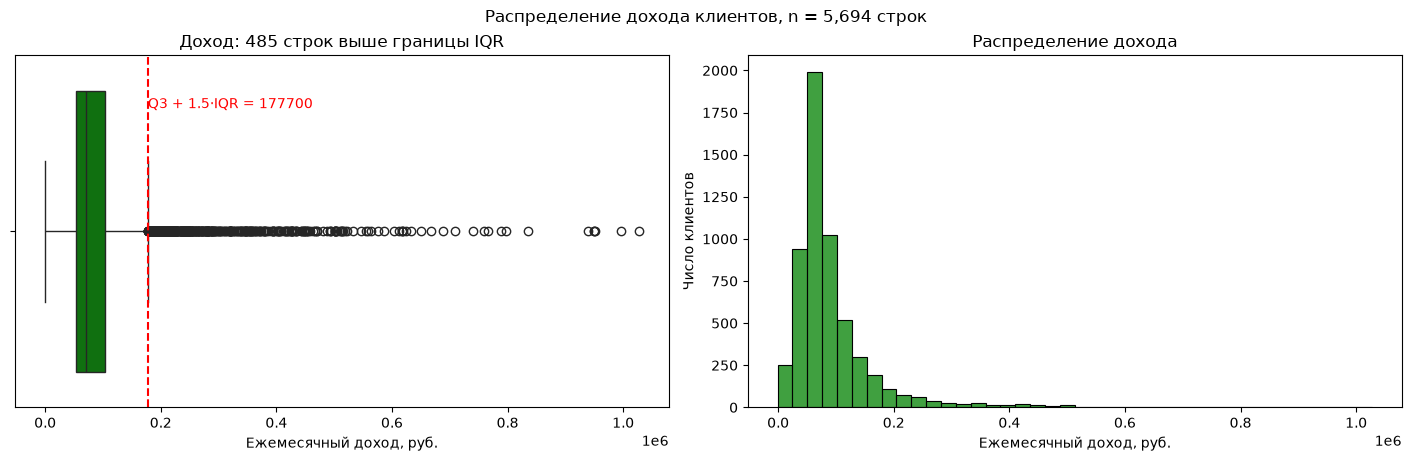

In [22]:
q = clients["monthly_income"]
q1, q3 = q.quantile([0.25, 0.75])
upper_iqr = q3 + 1.5 * (q3 - q1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), layout="constrained")

sns.boxplot(x=q, ax=axes[0], color="green")
axes[0].axvline(upper_iqr, color="red", ls="--")
axes[0].annotate(f"Q3 + 1.5·IQR = {upper_iqr:.0f}", xy=(upper_iqr, -0.35), color="red")
axes[0].set_title(f"Доход: {(q > upper_iqr).sum()} строк выше границы IQR")
axes[0].set_xlabel("Ежемесячный доход, руб.")

sns.histplot(clients["monthly_income"], bins=40, ax=axes[1], color="green")
axes[1].set_title("Распределение дохода")
axes[1].set_xlabel("Ежемесячный доход, руб.")
axes[1].set_ylabel("Число клиентов")

fig.suptitle(f"Распределение дохода клиентов, n = {len(clients):,} строк")
plt.show()

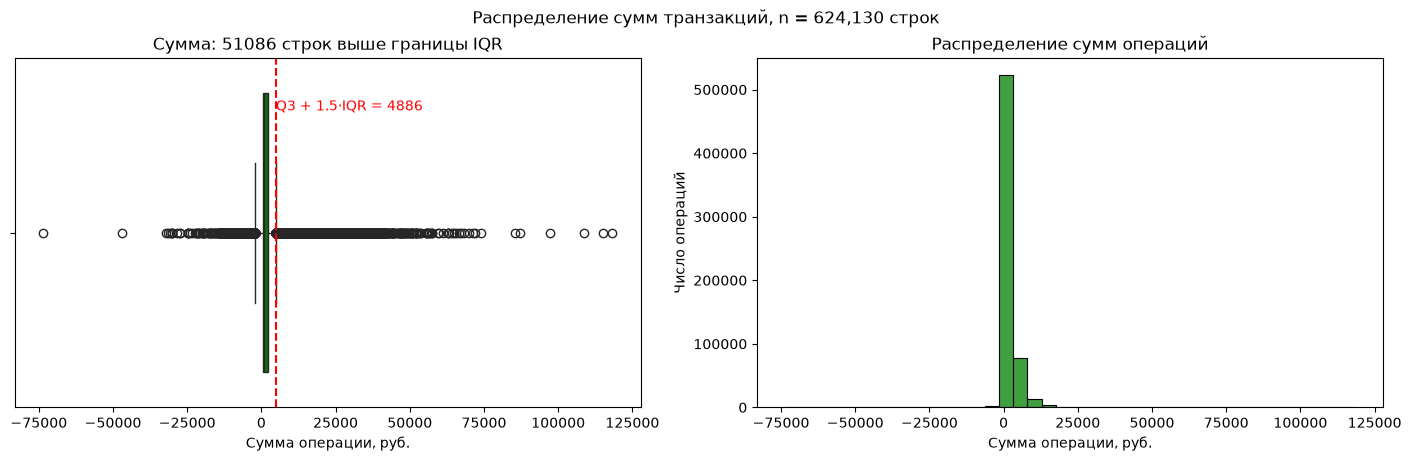

In [23]:
q = txn["amount"]
q1, q3 = q.quantile([0.25, 0.75])
upper_iqr = q3 + 1.5 * (q3 - q1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), layout="constrained")

sns.boxplot(x=q, ax=axes[0], color="green")
axes[0].axvline(upper_iqr, color="red", ls="--")
axes[0].annotate(f"Q3 + 1.5·IQR = {upper_iqr:.0f}", xy=(upper_iqr, -0.35), color="red")
axes[0].set_title(f"Сумма: {(q > upper_iqr).sum()} строк выше границы IQR")
axes[0].set_xlabel("Сумма операции, руб.")

sns.histplot(txn["amount"], bins=40, ax=axes[1], color="green")
axes[1].set_title("Распределение сумм операций")
axes[1].set_xlabel("Сумма операции, руб.")
axes[1].set_ylabel("Число операций")

fig.suptitle(f"Распределение сумм транзакций, n = {len(txn):,} строк")
plt.show()

Изучаем гистограммы и ящики с усами, видим хвосты справа в обеих ситуациях, однако большой доход или крупная операция это не всегда выброс, делаем доп проверку: доход по статусу клиента и сумма транзакции по категории траты

In [24]:
q1_inc, q3_inc = clients['monthly_income'].quantile([0.25, 0.75])
upper_iqr_income = q3_inc + 1.5 * (q3_inc - q1_inc)
outliers_income = clients[clients['monthly_income'] > upper_iqr_income]

print("Распределение сегментов среди клиентов с доходом выше IQR (%):")
print((outliers_income['segment'].value_counts(normalize=True) * 100).round(1))

Распределение сегментов среди клиентов с доходом выше IQR (%):
segment
Премиальный    50.5
Private        43.1
Зарплатный      4.9
Массовый        1.4
Name: proportion, dtype: float64


Видим, что клиенты с высоким доходом являются приватными или преальными, их высокий доход абсолютно логичен и не является выбросом. Есть также клиенты статуса зарплатный или массовый с высоким доходом, надо проверить дополнительно, смотрим на время нахождения в банке, источник дохода, количество операций и сумму трат. Сравниваем сумму трат с ежемесячным доходом и выводим только тех клиентов, которые зарабатывают в месяц больше, чем потратили за все время в банке

In [25]:
q1_inc, q3_inc = clients['monthly_income'].quantile([0.25, 0.75])
upper_iqr_income = q3_inc + 1.5 * (q3_inc - q1_inc)
current_date = pd.Timestamp('2025-06-30')
suspicious_income = clients[
    (clients['monthly_income'] > upper_iqr_income) & 
    (clients['segment'].isin(['Массовый', 'Зарплатный']))
].copy()
suspicious_income['days_in_bank'] = (current_date - suspicious_income['registration_date']).dt.days

txn_success = txn[txn['status'] == 'успешно']
suspicious_txn = txn_success[txn_success['client_id'].isin(suspicious_income['client_id'])]

txn_stats = suspicious_txn.groupby('client_id').agg(
    total_spent=('amount', 'sum'),
    txn_count=('txn_id', 'count'),
    avg_check=('amount', 'mean')
).reset_index()

check_31 = suspicious_income.merge(txn_stats, on='client_id', how='left').fillna({'total_spent': 0, 'txn_count': 0})

check_31 = check_31.sort_values('total_spent', ascending=False).reset_index(drop=True)

check_31_filtered = check_31[check_31['monthly_income'] > check_31['total_spent']]

print(f"Из {len(check_31)} клиентов, у {len(check_31_filtered)} доход в месяц больше трат за весь период:")

display(check_31_filtered[['client_id', 'segment', 'income_source', 'monthly_income', 'days_in_bank', 'txn_count', 'total_spent']])

Из 31 клиентов, у 13 доход в месяц больше трат за весь период:


,client_id,segment,income_source,monthly_income,days_in_bank,txn_count,total_spent
8,C004151,Зарплатный,Зарплата в нашем банке,434100.0,993,126,324860.44
17,C003856,Зарплатный,Зарплата в нашем банке,246600.0,950,79,230078.76
20,C003262,Зарплатный,Зарплата в нашем банке,187400.0,3633,105,183435.35
21,C005664,Массовый,Зарплата в другом банке,188100.0,3670,85,182430.70
22,C001343,Зарплатный,Зарплата в нашем банке,193700.0,3403,69,166544.11
23,C003494,Зарплатный,Зарплата в нашем банке,211400.0,2703,83,160643.59
24,C001486,Зарплатный,Не указан,190300.0,5065,60,133458.80
25,C000178,Массовый,Не указан,192500.0,1911,57,102415.17
26,C005528,Зарплатный,Зарплата в нашем банке,187100.0,2801,48,72181.77
27,C000553,Массовый,Не указан,216800.0,4328,40,68605.54


10 клиентов - активные пользователи. Совершили от 40 до 126 операций на суммы от 68 до 324 тыс. руб. Их доход логично подтверждается активностью трат.
3 клиента имеют длительное пребывание в банке(от 254 до 2103 дней) и высокий доход (180-190 тыс.), но совершили всего от 1 до 5 операций. Однако у всех троих источник дохода - "Зарплата в нашем банке". Это доказывает, что ошибки ввода нет, просто клиенты получают зарплату в банке, но тратят ее через другие каналы.

In [26]:
q1_t, q3_t = txn['amount'].quantile([0.25, 0.75])
upper_iqr_amount = q3_t + 1.5 * (q3_t - q1_t)
clients_for_merge = clients.drop_duplicates('client_id')[['client_id', 'segment']]
txn_seg = txn.merge(clients_for_merge, on='client_id', how='left')
outliers_txn = txn_seg[txn_seg['amount'] > upper_iqr_amount]
print(outliers_txn['category'].value_counts().head(5))

category
Одежда и обувь         26964
Развлечения и досуг     9516
АЗС                     5724
Кафе и рестораны        5470
Продукты                2842
Name: count, dtype: int64


Проверили категории трат у больших транзакций, в них действительно можно потратить много, так что это не выбросы

In [27]:
clients.loc[clients['monthly_income'] == -999, 'monthly_income'] = np.nan
income_median_by_group = clients.groupby('income_source', observed=True)['monthly_income'].transform('median')
clients['monthly_income'] = clients['monthly_income'].fillna(income_median_by_group)

Обратили показатель -999 на доходе в пропуск и заполнили медианами.

### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [28]:
rows_clients_before = len(clients)
rows_txn_before = len(txn)

clients = clients.drop_duplicates().reset_index(drop=True)
txn = txn.drop_duplicates().reset_index(drop=True)

deleted_clients = rows_clients_before - len(clients)
deleted_txn = rows_txn_before - len(txn)

print(f"CLIENTS ")
print(f"Было строк: {rows_clients_before} | Удалено полных дублей: {deleted_clients} | Стало: {len(clients)}\n")

print(f"TXN ")
print(f"Было строк: {rows_txn_before} | Удалено полных дублей: {deleted_txn} | Стало: {len(txn)}")

CLIENTS 
Было строк: 5694 | Удалено полных дублей: 40 | Стало: 5654

TXN 
Было строк: 624130 | Удалено полных дублей: 1308 | Стало: 622822


In [29]:
print(f"Исходно транзакций: {len(txn)}")

mask_period = (txn['txn_datetime'] >= '2024-01-01') & (txn['txn_datetime'] <= '2025-06-30')
txn_filtered = txn[mask_period].copy()
print(f"После фильтра по датам (2024 - 1 п/г 2025): {len(txn_filtered)} (удалено {len(txn) - len(txn_filtered)})")

valid_clients = set(clients['client_id'])
txn_filtered = txn_filtered[txn_filtered['client_id'].isin(valid_clients)]
print(f"После удаления клиентов не из справочника: {len(txn_filtered)}")


Исходно транзакций: 622822
После фильтра по датам (2024 - 1 п/г 2025): 621904 (удалено 918)
После удаления клиентов не из справочника: 591791


In [30]:
before = len(txn)
print(f"Было транзакций: {before}")

# Ищем и удаляем операции раньше открытия карты
temp_check = txn[['txn_id', 'client_id', 'txn_datetime']].merge(
    clients[['client_id', 'card_open_date']].drop_duplicates('client_id'), 
    on='client_id', how='inner'
)

bad_txn_ids = temp_check[temp_check['txn_datetime'] < temp_check['card_open_date']]['txn_id']

txn = txn[~txn['txn_id'].isin(bad_txn_ids)].copy()

print(f"Удалено операций: {len(bad_txn_ids)}")
print(f"Осталось после удаления операций раньше создания карты: {len(txn)}")

Было транзакций: 622822
Удалено операций: 1
Осталось после удаления операций раньше создания карты: 622821


Рассмотрим дубли по client_id

In [31]:
dup_clients = clients[clients.duplicated(subset=['client_id'], keep=False)].sort_values('client_id')

print(f"Всего строк с дублирующимся client_id: {len(dup_clients)}")
display(dup_clients[['client_id', 'segment', 'monthly_income', 'card_open_date', 'registration_date', 'branch_code']].head(10))

Всего строк с дублирующимся client_id: 30


,client_id,segment,monthly_income,card_open_date,registration_date,branch_code
629,C001493,Массовый,63100.0,2021-01-29,2016-12-06,00488
1535,C001493,Зарплатный,63100.0,2021-01-29,2016-12-06,00488
143,C001937,Массовый,67200.0,2016-12-26,2015-01-08,00830
3917,C001937,Массовый,67200.0,2016-12-26,2015-01-08,00830
3888,C002169,Private,56800.0,2021-11-28,2016-06-05,00424
3506,C002169,Массовый,56800.0,2021-11-28,2016-06-05,00424
3109,C002843,Массовый,67200.0,2018-11-22,2018-03-10,00339
2119,C002843,Массовый,67200.0,2018-11-22,2018-03-10,00339
3369,C002860,Зарплатный,70600.0,2023-11-08,2021-09-12,00936
2745,C002860,Премиальный,70600.0,2023-11-08,2021-09-12,00936


Видим, что у клиентов меняется статус, скорее всего это ошибка выгрузки, возможно данные выгружались группами по статусу, а статус некоторых клиентов изменился прямо во время выгрузки, значит оставляем строки с более высоким статусом, ведь зачастую статус клиентов растет. Но есть и строки без изменения статуса, рассмотрим их подробнее.

In [32]:
dup_clients = clients[clients.duplicated(subset=['client_id'], keep=False)]
same_segment_dups = dup_clients.groupby('client_id').filter(lambda x: x['segment'].nunique() == 1)

print(f"Клиенты с одинаковым сегментом, но задублированные: {same_segment_dups['client_id'].nunique()}")
display(same_segment_dups.sort_values('client_id'))

Клиенты с одинаковым сегментом, но задублированные: 5


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in,is_surveyed,age
143,C001937,1979-10-06,Ж,Нижний Новгород,Массовый,Базовый,Дебетовая,2015-01-08,2016-12-26,Не указан,67200.0,Нет,NaT,NaN,00830,Да,0,45
3917,C001937,1979-10-06,Ж,Новосибирск,Массовый,Базовый,Дебетовая,2015-01-08,2016-12-26,Не указан,67200.0,Нет,NaT,NaN,00830,Да,0,45
2119,C002843,1978-10-03,М,Екатеринбург,Массовый,Серебро,Дебетовая,2018-03-10,2018-11-22,Не указан,67200.0,Да,2024-01-01,NaN,00339,Да,0,46
3109,C002843,1978-10-03,М,Санкт-Петербург,Массовый,Серебро,Дебетовая,2018-03-10,2018-11-22,Не указан,67200.0,Да,2024-01-01,NaN,00339,Да,0,46
854,C003563,1986-07-24,М,Казань,Зарплатный,Базовый,Дебетовая,2021-10-16,2022-10-06,Зарплата в нашем банке,92500.0,Да,2024-06-01,NaN,00556,Да,0,38
2908,C003563,1986-07-24,М,Екатеринбург,Зарплатный,Базовый,Дебетовая,2021-10-16,2022-10-06,Зарплата в нашем банке,92500.0,Да,2024-06-01,NaN,00556,Да,0,38
2707,C004947,1969-04-14,М,Санкт-Петербург,Зарплатный,Золото,Дебетовая,2014-10-26,2016-10-19,Зарплата в нашем банке,104400.0,Да,2025-04-01,5.0,00216,Да,1,56
3722,C004947,1969-04-14,М,Екатеринбург,Зарплатный,Золото,Дебетовая,2014-10-26,2016-10-19,Зарплата в нашем банке,104400.0,Да,2025-04-01,5.0,00216,Да,1,56
637,C005545,1971-08-24,Ж,Нижний Новгород,Зарплатный,Базовый,Дебетовая,2023-07-21,2024-11-21,Зарплата в нашем банке,69700.0,Да,2024-02-01,3.0,00125,Да,1,53
856,C005545,1971-08-24,Ж,Екатеринбург,Зарплатный,Базовый,Дебетовая,2023-07-21,2024-11-21,Зарплата в нашем банке,69700.0,Да,2024-02-01,3.0,00125,Да,1,53


Видим, что меняется только город, посмотреть, какой город более верный и свежее мы не можем, поэтому берем любой из двух, тк таких данных всего 5 строк из 59 тысяч, на анализ это не повлияет.

In [33]:
dup_txn = txn[txn.duplicated(subset=['txn_id'], keep=False)].copy()

txn_compare = dup_txn.groupby('txn_id').agg(
    count=('txn_id', 'size'),
    unique_dates=('txn_datetime', 'nunique'),
    unique_statuses=('status', 'nunique'),
    unique_amounts=('amount', 'nunique')
)

print(f"Всего txn_id с дублями: {len(txn_compare)}")
print(f"Отличаются по времени (txn_datetime): {(txn_compare['unique_dates'] > 1).sum()}")
print(f"Отличаются по статусу (status): {(txn_compare['unique_statuses'] > 1).sum()}")
print(f"Отличаются по сумме (amount): {(txn_compare['unique_amounts'] > 1).sum()}")

print("\nПримеры дублей:")
display(dup_txn.sort_values('txn_id').head(10))

Всего txn_id с дублями: 192
Отличаются по времени (txn_datetime): 192
Отличаются по статусу (status): 0
Отличаются по сумме (amount): 0

Примеры дублей:


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
846,100838,C000267,2024-01-02 09:59:23,354.45,RUB,Продукты,5411,Карта,успешно
847,100838,C000267,2024-01-02 00:00:00,354.45,RUB,Продукты,5411,Карта,успешно
4874,104864,C002664,2024-01-06 12:35:48,1226.79,RUB,Онлайн-сервисы,5815,Карта,успешно
4875,104864,C002664,2024-01-06 00:00:00,1226.79,RUB,Онлайн-сервисы,5815,Карта,успешно
5685,105675,C003319,2024-01-06 18:12:31,25.04,RUB,Транспорт,4111,Карта,успешно
5687,105675,C003319,2024-01-06 00:00:00,25.04,RUB,Транспорт,4111,Карта,успешно
11399,111383,C004246,2024-01-13 00:00:00,1364.23,RUB,Продукты,5411,СБП,успешно
11400,111383,C004246,2024-01-13 20:27:22,1364.23,RUB,Продукты,5411,СБП,успешно
13375,113358,C000795,2024-01-16 00:00:00,1500.32,RUB,Кафе и рестораны,5812,СБП,успешно
13376,113358,C000795,2024-01-16 13:55:58,1500.32,RUB,Кафе и рестораны,5812,СБП,успешно


Смотрим на дубли по txn_id, видим, что отличие только в столбике txn_datetime, просто где-то время было указано, а где-то нет и заполнялось на 00:00:00 при изменении типа столбика. Оставляем строки с временем, отличным от нуля

In [34]:
n_clients_before = len(clients)

segment_rank = {'Массовый': 1, 'Зарплатный': 2, 'Премиальный': 3, 'Private': 4}
clients['segment_rank'] = clients['segment'].map(segment_rank)

clients = clients.sort_values(['client_id', 'segment_rank'])
clients = clients.drop_duplicates(subset=['client_id'], keep='last')
clients = clients.drop(columns=['segment_rank']).reset_index(drop=True)

n_clients_after = len(clients)

n_txn_before = len(txn)

txn = txn.copy() 
txn['has_time'] = (txn['txn_datetime'].dt.hour != 0) | (txn['txn_datetime'].dt.minute != 0) | (txn['txn_datetime'].dt.second != 0)

txn = txn.sort_values(['txn_id', 'has_time', 'txn_datetime'])
txn = txn.drop_duplicates(subset=['txn_id'], keep='last')
txn = txn.drop(columns=['has_time']).reset_index(drop=True)

n_txn_after = len(txn)

print(f"CLIENTS")
print(f"Было строк: {n_clients_before} | Стало: {n_clients_after} | Удалено дублей: {n_clients_before - n_clients_after}")
print(f"Проверка: осталось дублей по client_id: {clients['client_id'].duplicated().sum()}\n")

print(f"TXN")
print(f"Было строк: {n_txn_before} | Стало: {n_txn_after} | Удалено дублей: {n_txn_before - n_txn_after}")
print(f"Проверка: осталось дублей по txn_id: {txn['txn_id'].duplicated().sum()}")

CLIENTS
Было строк: 5654 | Стало: 5639 | Удалено дублей: 15
Проверка: осталось дублей по client_id: 0

TXN
Было строк: 622821 | Стало: 622629 | Удалено дублей: 192
Проверка: осталось дублей по txn_id: 0


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [35]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

In [36]:
new_logs_duplicates = [
    {
        "field": "client_id", 
        "issue": "полные дубли строк", 
        "scope": "clients", 
        "n_rows": deleted_clients, 
        "value_before": "дубликаты", 
        "action": "удалено", 
        "value_after": "уникальные строки", 
        "rationale": "технические дубли выгрузки, искажают статистику и метрику"
    },
    {
        "field": "txn_id", 
        "issue": "полные дубли строк", 
        "scope": "txn", 
        "n_rows": deleted_txn, 
        "value_before": "дубликаты", 
        "action": "удалено", 
        "value_after": "уникальные строки", 
        "rationale": "технические дубли выгрузки, приводили к двойному счету операций"
    }
]

cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_logs_duplicates)], ignore_index=True)

In [37]:
new_logs = [
    {
        "field": "txn_datetime", "issue": "строковый формат (с временем и без)",
        "scope": "transactions", "n_rows": len(txn),
        "value_before": "str ('2023-11-23 09:00:42', '2023-11-26')", "action": "конвертация",
        "value_after": "datetime64", "rationale": "для корректного расчета периодов"
    },
    {
        "field": "txn_datetime, birth_date, registration_date, card_open_date, app_last_login", 
        "issue": "строковый формат на датах", "scope": "clients", "n_rows": len(clients),
        "value_before": "str ('1993-11-03', '23.09.2022', '2024-03')", "action": "конвертация",
        "value_after": "datetime64", "rationale": "для расчета возраста, стажа и давности входа"
    }
]

cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_logs)], ignore_index=True)

In [38]:
new_logs2 = [
    {
        "field": "category", 
        "issue": "разнобой в написании, 12 уникальных значений вместо 9", 
        "scope": "txn", 
        "n_rows": 51801,  
        "value_before": "'Кафе/рестораны', 'кафе и рестораны', 'Связь и Интернет'", 
        "action": "исправлено", 
        "value_after": "9 уникальных категорий", 
        "rationale": "устранение дублей категорий"
    },
    {
        "field": "city", 
        "issue": "разный регистр, приставки, сокращения (17 вариантов)", 
        "scope": "clients", 
        "n_rows": 1685, 
        "value_before": "'г. Москва', ' москва', 'СПб', 'ЕКАТЕРИНБУРГ'", 
        "action": "нормализация", 
        "value_after": "6 городов", 
        "rationale": "устранение дублей категорий"
    },
    {
        "field": "cat_cols (segment, city, category и др.)", 
        "issue": "неоптимальный тип данных для полей с малым числом уникальных значений", 
        "scope": "clients, txn", 
        "n_rows": len(clients) + len(txn), 
        "value_before": "str", 
        "action": "изменение типа", 
        "value_after": "category", 
        "rationale": "экономия оперативной памяти"
    }
]
cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_logs2)], ignore_index=True)

In [39]:
new_log_33_app_login = [{
    "field": "app_last_login", 
    "issue": "пропуски 38.01%", 
    "scope": "clients", 
    "n_rows": 2161, 
    "value_before": "NaN", 
    "action": "оставлено", 
    "value_after": "NaN", 
    "rationale": "пропуск неслучаен, клиент не имеет приложения или ни разу не заходил"
}]

cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_log_33_app_login)], ignore_index=True)

In [40]:
new_logs3 = [ {
        "field": "monthly_income", "issue": "пропуски 8.88%", "scope": "clients", 
        "n_rows": 504, "value_before": "NaN", 
        "action": "заполнение", "value_after": "медиана по группам income_source", 
        "rationale": "зависимость от источника дохода"
    }]
cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_logs3)], ignore_index=True)

In [41]:
new_logs_33_score = [{
    "field": "satisfaction_score", 
    "issue": "пропуски 59.52%", 
    "scope": "clients", 
    "n_rows": 3390, 
    "value_before": "NaN", 
    "action": "создан флаг", 
    "value_after": "NaN, колонка is_surveyed", 
    "rationale": "заполнение 60% данных исказит распределение, факт отсутствия оценки сохранен как отдельный признак"
}]
cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_logs_33_score)], ignore_index=True)

In [42]:
new_log_34 = [{
    "field": "monthly_income", 
    "issue": "техническое значение -999 (маркер отсутствия данных)", 
    "scope": "clients", 
    "n_rows": 39, 
    "value_before": "-999.0", 
    "action": "заменено на NaN и заполнено медианой по группам", 
    "value_after": "медиана по группам income_source", 
    "rationale": "доход не может быть отрицательным"
}]

cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_log_34)], ignore_index=True)

In [43]:
new_log_34_refunds = [{
    "field": "amount", 
    "issue": "отрицательные значения (до -73k)", 
    "scope": "txn", 
    "n_rows": 7488, 
    "value_before": "отрицательные суммы", 
    "action": "оставлено", 
    "value_after": "без изменений", 
    "rationale": "все 7488 строк соответствуют статусу 'возврат' (особенность учета)"
}]
cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_log_34_refunds)], ignore_index=True)

In [44]:
new_log_34_outliers = [{
    "field": "monthly_income", 
    "issue": "выбросы выше границы IQR", 
    "scope": "clients", 
    "n_rows": 485, 
    "value_before": "> 177 700 руб.", 
    "action": "оставлено", 
    "value_after": "без изменений", 
    "rationale": "Основная часть в статусе Премиум/Private. Остальные проверены по сумме трат и количеству операций"
}]

cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_log_34_outliers)], ignore_index=True)

In [45]:
new_log_34_txn_outliers = [{
    "field": "amount", 
    "issue": "выбросы выше границы IQR", 
    "scope": "txn", 
    "n_rows": 51086, 
    "value_before": "> 4886 руб.", 
    "action": "оставлено", 
    "value_after": "без изменений", 
    "rationale": "Крупные суммы распределены по логичным категориям (Одежда и обувь, Развлечения, АЗС, Кафе), что подтверждает реальность трат."
}]

cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_log_34_txn_outliers)], ignore_index=True)

In [46]:
new_logs_35 = [
    {
        "field": "txn_datetime", 
        "issue": "выход за заявленный период (2023 и 2025-2026)", 
        "scope": "txn", 
        "n_rows": 918, 
        "value_before": "2023-11-23 .. 2026-07-26", 
        "action": "отфильтровано (удалено)", 
        "value_after": "2024-01-01 .. 2025-06-30", 
        "rationale": "для корректного сравнения базового и оцениваемого периодов"
    },
    {
        "field": "client_id", 
        "issue": "операции клиентов, отсутствующих в справочнике (битые ссылки)", 
        "scope": "txn", 
        "n_rows": 30113, 
        "value_before": "352 уникальных ID-призраков", 
        "action": "отфильтровано (удалено)", 
        "value_after": "только клиенты из справочника", 
        "rationale": "невозможно определить признаки (сегмент, возраст) для формирования групп кампании"
    },
    {
        "field": "txn_datetime", 
        "issue": "логическая ошибка (операция раньше открытия карты)", 
        "scope": "txn", 
        "n_rows": 1, 
        "value_before": "дата операции < card_open_date", 
        "action": "удалено", 
        "value_after": "-", 
        "rationale": "нарушение хронологии"
    }
]

cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_logs_35)], ignore_index=True)
print("Записи в журнал добавлены!")

Записи в журнал добавлены!


In [47]:
new_log_dups = [{
    "field": "client_id, segment, city",
    "issue": "конфликтующие дубли (разный статус или город)",
    "scope": "clients",
    "n_rows": 15,
    "value_before": "30 строк (15 дублей)",
    "action": "удалено (оставлена строка с более высоким статусом",
    "value_after": "15 уникальных строк",
    "rationale": "в банковской практике статус чаще растет, поэтому при разнице сегментов выбран старший. При разнице городов просто оставлена 1 запись"
}]

cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_log_dups)], ignore_index=True)
print("Запись про дубли добавлена в журнал!")

Запись про дубли добавлена в журнал!


In [48]:
new_log_txn_dups = [{
    "field": "txn_id", 
    "issue": "технические дубли (разное время, одинаковые статус/сумма)", 
    "scope": "txn", 
    "n_rows": 192, 
    "value_before": "192 дублирующихся txn_id", 
    "action": "удалено", 
    "value_after": "уникальные операции", 
    "rationale": "одни и те же транзакции были выгружены со временем и без, оставлены записи со временем"
}]
cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_log_txn_dups)], ignore_index=True)

## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

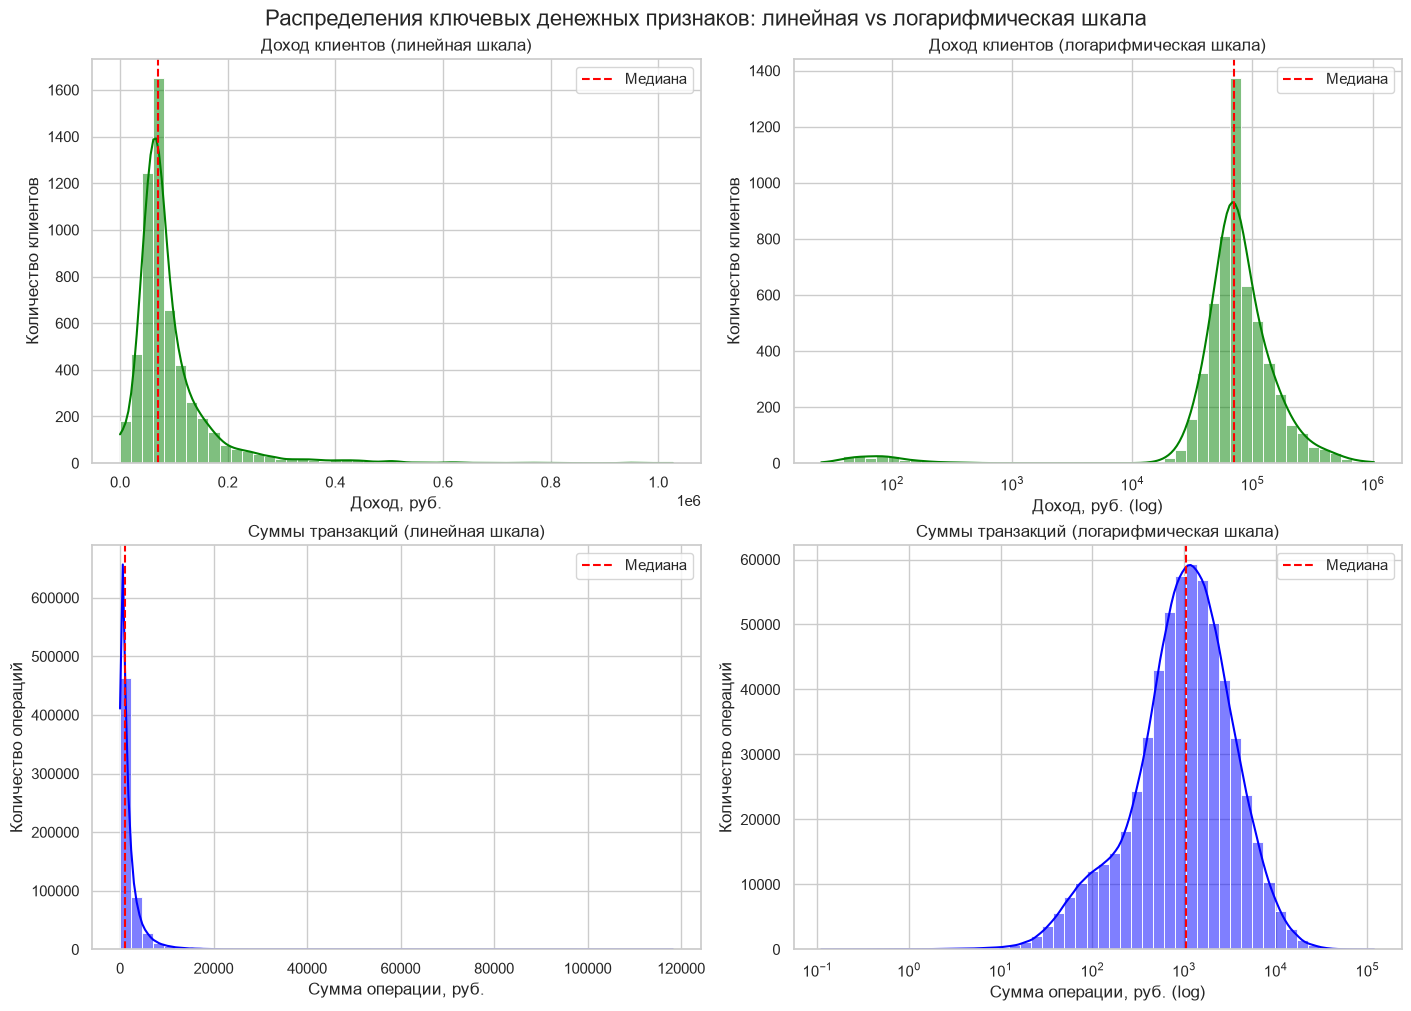

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(14, 10), layout="constrained")
axes = axes.flatten()

sns.histplot(clients['monthly_income'], bins=50, ax=axes[0], color="green", kde=True)
axes[0].set_title('Доход клиентов (линейная шкала)')
axes[0].set_xlabel('Доход, руб.')
axes[0].set_ylabel('Количество клиентов')
axes[0].axvline(clients['monthly_income'].median(), color='red', linestyle='--', label='Медиана')
axes[0].legend()

sns.histplot(clients['monthly_income'], bins=50, ax=axes[1], color="green", kde=True, log_scale=True)
axes[1].set_title('Доход клиентов (логарифмическая шкала)')
axes[1].set_xlabel('Доход, руб. (log)')
axes[1].set_ylabel('Количество клиентов')
axes[1].axvline(clients['monthly_income'].median(), color='red', linestyle='--', label='Медиана')
axes[1].legend()

txn_pos = txn[(txn['amount'] > 0) & (txn['status'] == 'успешно')]

sns.histplot(txn_pos['amount'], bins=50, ax=axes[2], color="blue", kde=True)
axes[2].set_title('Суммы транзакций (линейная шкала)')
axes[2].set_xlabel('Сумма операции, руб.')
axes[2].set_ylabel('Количество операций')
axes[2].axvline(txn_pos['amount'].median(), color='red', linestyle='--', label='Медиана')
axes[2].legend()

sns.histplot(txn_pos['amount'], bins=50, ax=axes[3], color="blue", kde=True, log_scale=True)
axes[3].set_title('Суммы транзакций (логарифмическая шкала)')
axes[3].set_xlabel('Сумма операции, руб. (log)')
axes[3].set_ylabel('Количество операций')
axes[3].axvline(txn_pos['amount'].median(), color='red', linestyle='--', label='Медиана')
axes[3].legend()

fig.suptitle('Распределения ключевых денежных признаков: линейная vs логарифмическая шкала', fontsize=16)
plt.show()

monthly_income: На лог-шкале видно, что база делится на основную массу и тяжелый хвост справа - клиентов с доходом до 1 млн. руб. Наличие клиентов с доходом 100–1000 руб. объясняется наличием в базе студентов или пенсионеров.
amount: Распределение сумм успешных транзакций на лог-шкале похоже на нормальное, но на линейном графике видно, что это неправда. Медианный чек составляет около 1 000 руб. Подавляющее большинство операций — это ежедневные траты от 100 до 10 000 руб.
Метрика активности должна опираться на количество операций или медианный чек, чтобы крупные разовые покупки VIP-клиентов не маскировали снижение ежедневной активности массового сегмента.

### 5.2. Частотные характеристики категориальных признаков

C:\Users\aleksandr.shepilov\AppData\Local\Temp\ipykernel_4436\3370161735.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clients, x='segment', ax=axes[0, 0], palette='viridis', order=clients['segment'].value_counts().index)
C:\Users\aleksandr.shepilov\AppData\Local\Temp\ipykernel_4436\3370161735.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clients, x='loyalty_tier', ax=axes[0, 1], palette='viridis', order=clients['loyalty_tier'].value_counts().index)
C:\Users\aleksandr.shepilov\AppData\Local\Temp\ipykernel_4436\3370161735.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue`

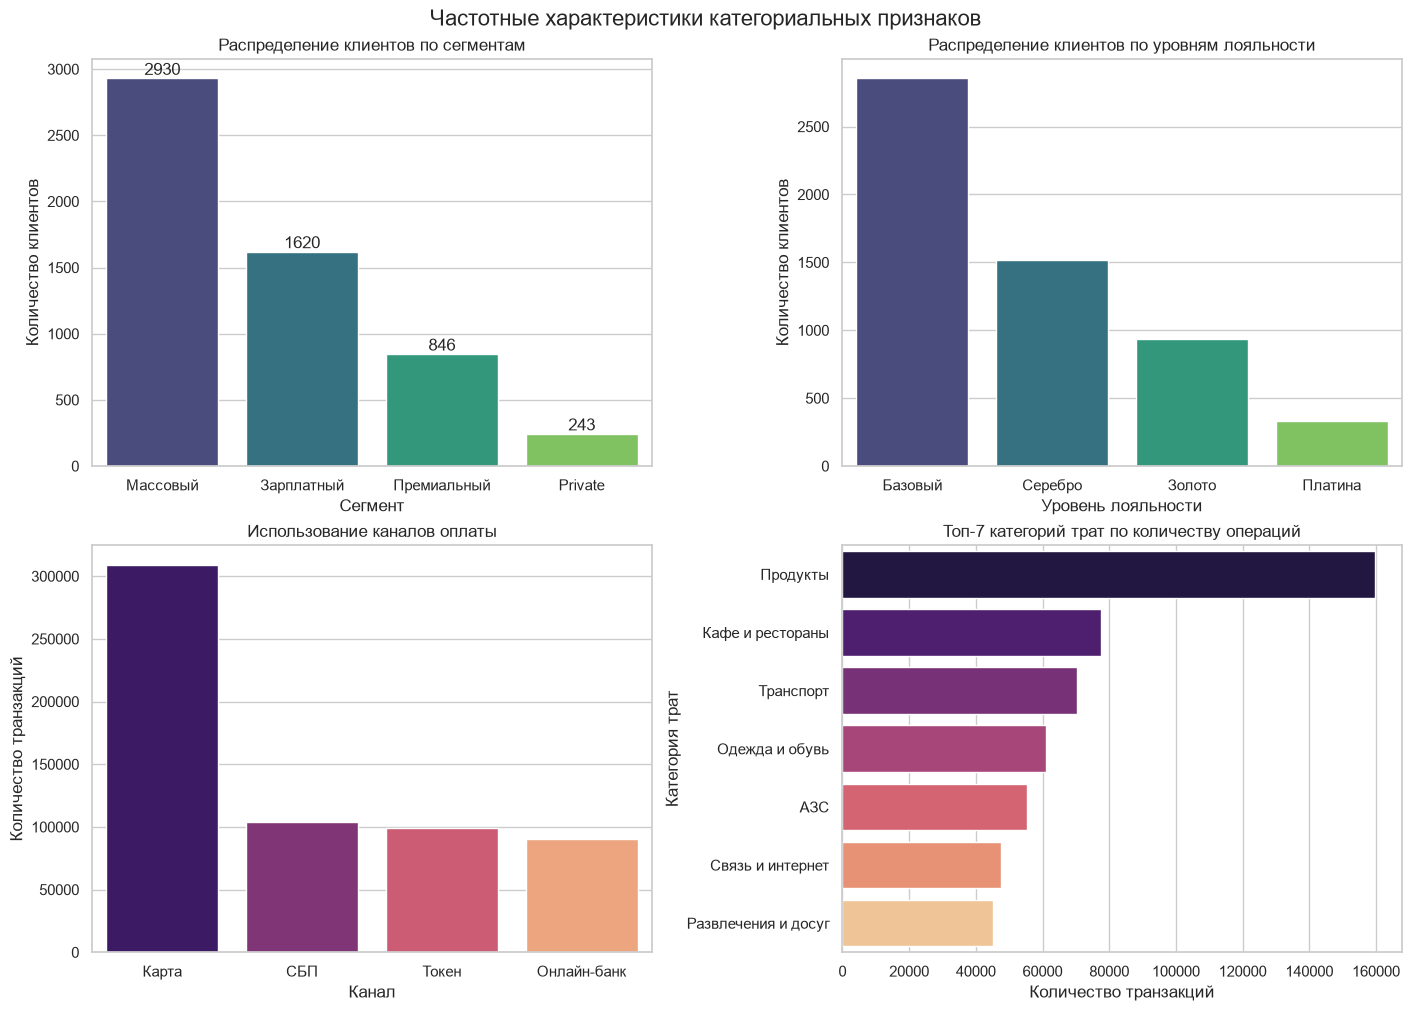

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10), layout="constrained")

sns.countplot(data=clients, x='segment', ax=axes[0, 0], palette='viridis', order=clients['segment'].value_counts().index)
axes[0, 0].set_title('Распределение клиентов по сегментам')
axes[0, 0].set_xlabel('Сегмент')
axes[0, 0].set_ylabel('Количество клиентов')
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='bottom')

sns.countplot(data=clients, x='loyalty_tier', ax=axes[0, 1], palette='viridis', order=clients['loyalty_tier'].value_counts().index)
axes[0, 1].set_title('Распределение клиентов по уровням лояльности')
axes[0, 1].set_xlabel('Уровень лояльности')
axes[0, 1].set_ylabel('Количество клиентов')

sns.countplot(data=txn_pos, x='channel', ax=axes[1, 0], palette='magma', order=txn_pos['channel'].value_counts().index)
axes[1, 0].set_title('Использование каналов оплаты')
axes[1, 0].set_xlabel('Канал')
axes[1, 0].set_ylabel('Количество транзакций')

top_categories = txn_pos['category'].value_counts().head(7).index
sns.countplot(data=txn_pos[txn_pos['category'].isin(top_categories)], 
              y='category', ax=axes[1, 1], palette='magma', order=top_categories)
axes[1, 1].set_title('Топ-7 категорий трат по количеству операций')
axes[1, 1].set_xlabel('Количество транзакций')
axes[1, 1].set_ylabel('Категория трат')

fig.suptitle('Частотные характеристики категориальных признаков', fontsize=16)
plt.show()

Клиентская база сильно смещена в сторону Массового сегмента и Зарплатного. Вместе они составляют около 80% всех клиентов. График уровня лояльности ожидаемо похож, основные уровни лояльности базовый и серебро. Премиальный и Private сегменты малочисленны, но как было выяснено при работе с выбросами. они совершают основную часть больших трат.

Взглянув на каналы оплаты определяем, что транзакций, совершенных картой, примерно 50% от всех операций. Поэтому если мы будем оценивать активность только по входам в мобильное приложение, то упустим реальную активность использования пластиковой карточки.
В категориях трат наблюдаем ожидаемую ситуацию, основное количетво операций - это товары повседневного спроса, а именно продукты, кафе и рестораны, при анализе активности надо обратить внимание на эти категории, тк если клиент перестал делать повседневные траты, то возможно он поменял банк. 

### 5.3. Динамика по месяцам

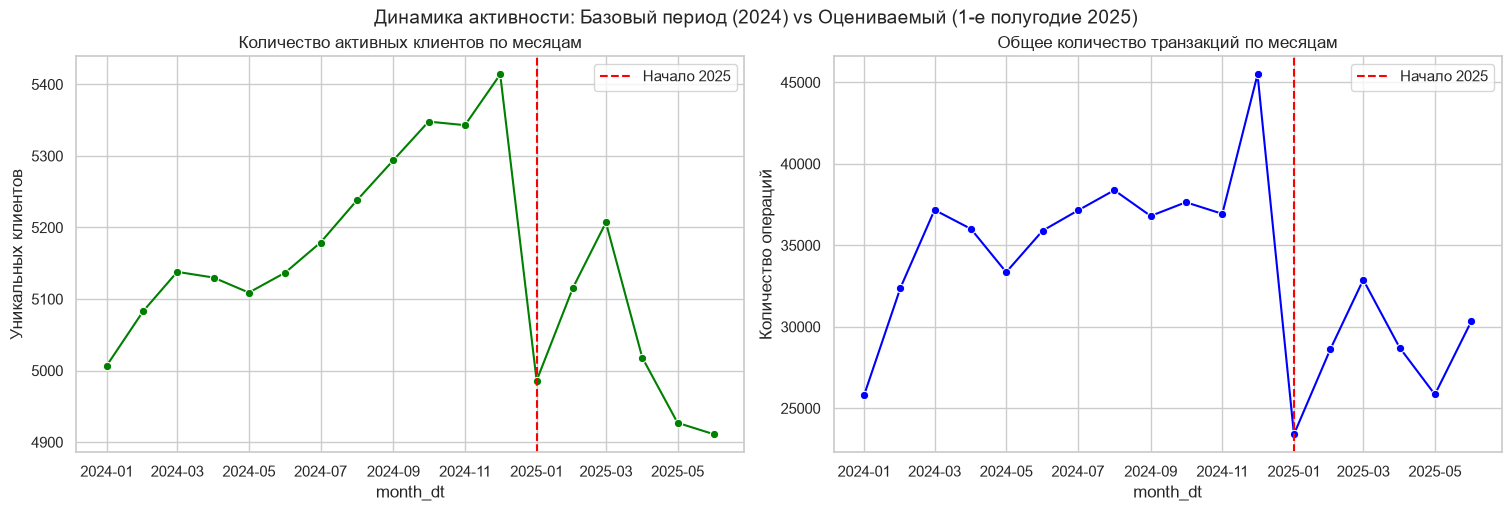

В СРЕДНЕМ ЗА МЕСЯЦ
Клиенты: 1п/г 2024 = 5101, 1п/г 2025 = 5028
Падение клиентов: -1.43%

Транзакции: 1п/г 2024 = 33436, 1п/г 2025 = 28302
Падение транзакций: -15.36%


In [51]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

txn_success = txn[txn['status'] == 'успешно'].copy()

txn_success = txn_success[
    (txn_success['txn_datetime'] >= '2024-01-01') & 
    (txn_success['txn_datetime'] <= '2025-06-30 23:59:59')
]

txn_success['month'] = txn_success['txn_datetime'].dt.to_period('M')

monthly_stats = txn_success.groupby('month').agg(
    active_clients=('client_id', 'nunique'),
    total_txn=('txn_id', 'count')
).reset_index()

monthly_stats['month_dt'] = monthly_stats['month'].dt.to_timestamp()
monthly_stats['year'] = monthly_stats['month_dt'].dt.year 
monthly_stats['month_num'] = monthly_stats['month_dt'].dt.month

fig, axes = plt.subplots(1, 2, figsize=(15, 5), layout="constrained")
sns.lineplot(data=monthly_stats, x='month_dt', y='active_clients', marker='o', ax=axes[0], color='green')
axes[0].axvline(pd.Timestamp('2025-01-01'), color='red', linestyle='--', label='Начало 2025')
axes[0].set_title('Количество активных клиентов по месяцам')
axes[0].set_ylabel('Уникальных клиентов')
axes[0].legend()

sns.lineplot(data=monthly_stats, x='month_dt', y='total_txn', marker='o', ax=axes[1], color='blue')
axes[1].axvline(pd.Timestamp('2025-01-01'), color='red', linestyle='--', label='Начало 2025')
axes[1].set_title('Общее количество транзакций по месяцам')
axes[1].set_ylabel('Количество операций')
axes[1].legend()
fig.suptitle('Динамика активности: Базовый период (2024) vs Оцениваемый (1-е полугодие 2025)', fontsize=14)
plt.show()

monthly_h1 = monthly_stats[monthly_stats['month_num'] <= 6]

avg_stats = monthly_h1.groupby('year').agg(
    avg_clients=('active_clients', 'mean'),
    avg_txn=('total_txn', 'mean')
).reset_index()

avg_2024_c = avg_stats[avg_stats['year'] == 2024]['avg_clients'].values[0]
avg_2025_c = avg_stats[avg_stats['year'] == 2025]['avg_clients'].values[0]
drop_c = ((avg_2025_c - avg_2024_c) / avg_2024_c) * 100

avg_2024_t = avg_stats[avg_stats['year'] == 2024]['avg_txn'].values[0]
avg_2025_t = avg_stats[avg_stats['year'] == 2025]['avg_txn'].values[0]
drop_t = ((avg_2025_t - avg_2024_t) / avg_2024_t) * 100

print("В СРЕДНЕМ ЗА МЕСЯЦ")
print(f"Клиенты: 1п/г 2024 = {avg_2024_c:.0f}, 1п/г 2025 = {avg_2025_c:.0f}")
print(f"Падение клиентов: {drop_c:.2f}%\n")

print(f"Транзакции: 1п/г 2024 = {avg_2024_t:.0f}, 1п/г 2025 = {avg_2025_t:.0f}")
print(f"Падение транзакций: {drop_t:.2f}%")

Рассмотрев количество успешных транзакций и активных клиентов (хотя бы одна транзакция) по месяцам, а также посчитав среднее за полугодия, можно заметить, что количество активных клиентов в оцениваемом периоде (с начала 2025 года) падает на 1.43%, что в целом не критично по сравнению с падением количества транзакций на 15.36%. Это говорит о том, что клиенты почему-то стали меньше платить через наш банк. То есть при выделении групп надо искать не тех, кто ушел из банка, а кто снизил активность по каким-то причинам. 

Также по графикам можно наблюдать, что в период новогодних праздников количество активных клиентов и успешных транзакции имеет пиковую высоту, что говорит нам о том, что базовый и оцениваемый период надо сравнивать по одним и тем же месяцам. Также видим,  что с февраля до конца марта количество активных клиентов растет как 2025, так и в 2024 году, проблемы начинают наблюдаться с начала апреля 2025 года, падение количества операций и транцакций более крутое, чем в 2024 году, более того количество активных клиентов после апреля 2025 года не растет до конца рассматриваемого нами периода, это может говорить об уходе клиентов из банка. 

### 5.4. Разрезы и связи между признаками

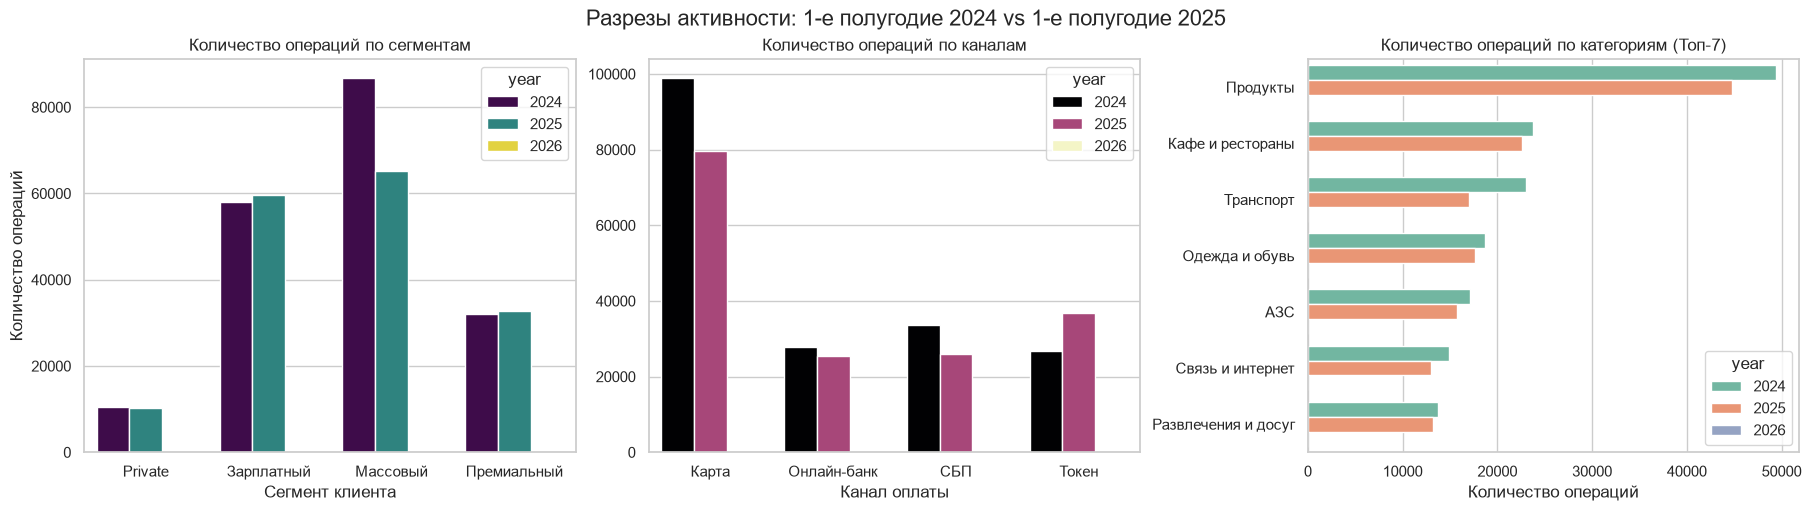

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

txn_success = txn[txn['status'] == 'успешно'].copy()

txn_success['year'] = txn_success['txn_datetime'].dt.year
txn_h1 = txn_success[txn_success['txn_datetime'].dt.month <= 6].copy()

clients_seg = clients.drop_duplicates('client_id')[['client_id', 'segment']]
txn_h1 = txn_h1.merge(clients_seg, on='client_id', how='inner')

fig, axes = plt.subplots(1, 3, figsize=(18, 5), layout="constrained")

sns.countplot(data=txn_h1, x='segment', hue='year', ax=axes[0], palette='viridis')
axes[0].set_title('Количество операций по сегментам')
axes[0].set_xlabel('Сегмент клиента')
axes[0].set_ylabel('Количество операций')

sns.countplot(data=txn_h1, x='channel', hue='year', ax=axes[1], palette='magma')
axes[1].set_title('Количество операций по каналам')
axes[1].set_xlabel('Канал оплаты')
axes[1].set_ylabel('')

top_cat = txn_h1['category'].value_counts().head(7).index
sns.countplot(data=txn_h1[txn_h1['category'].isin(top_cat)], y='category', hue='year', ax=axes[2], palette='Set2', order=top_cat)
axes[2].set_title('Количество операций по категориям (Топ-7)')
axes[2].set_xlabel('Количество операций')
axes[2].set_ylabel('')

fig.suptitle('Разрезы активности: 1-е полугодие 2024 vs 1-е полугодие 2025', fontsize=16)
plt.show()

Как упоминалось ранее основное внимание при изучении активности уделяем количеству успешных транзакций, а не клиентов, смотрим на разрезы по признакам. 

По первому графику хорошо заметно, что частота транзакций была потеряна только в массовом сегменте. 

Рассмотрев график с каналом оплаты видим, что количество операций по картам уппало почти на 20%, а точнее на 20 тысяч операций из 100 тысяч, возможно они просто перешли на оплату через Токен, тк мы видим, что эта категория выросла примерно на 12 тысяч операций. 

На третьем графике мы видим, что количество транзакций упало во всех категориях трат, основные потери отмечаем в категориях "Продукты" и "Транспорт", это повседневные траты, клиенты перестали пользоваться банком на ежедневной основе, можно предположить, что клиентов не устраивают условия банка, например, отутствие кешбека или бонусов за количество проведенных транзакций.

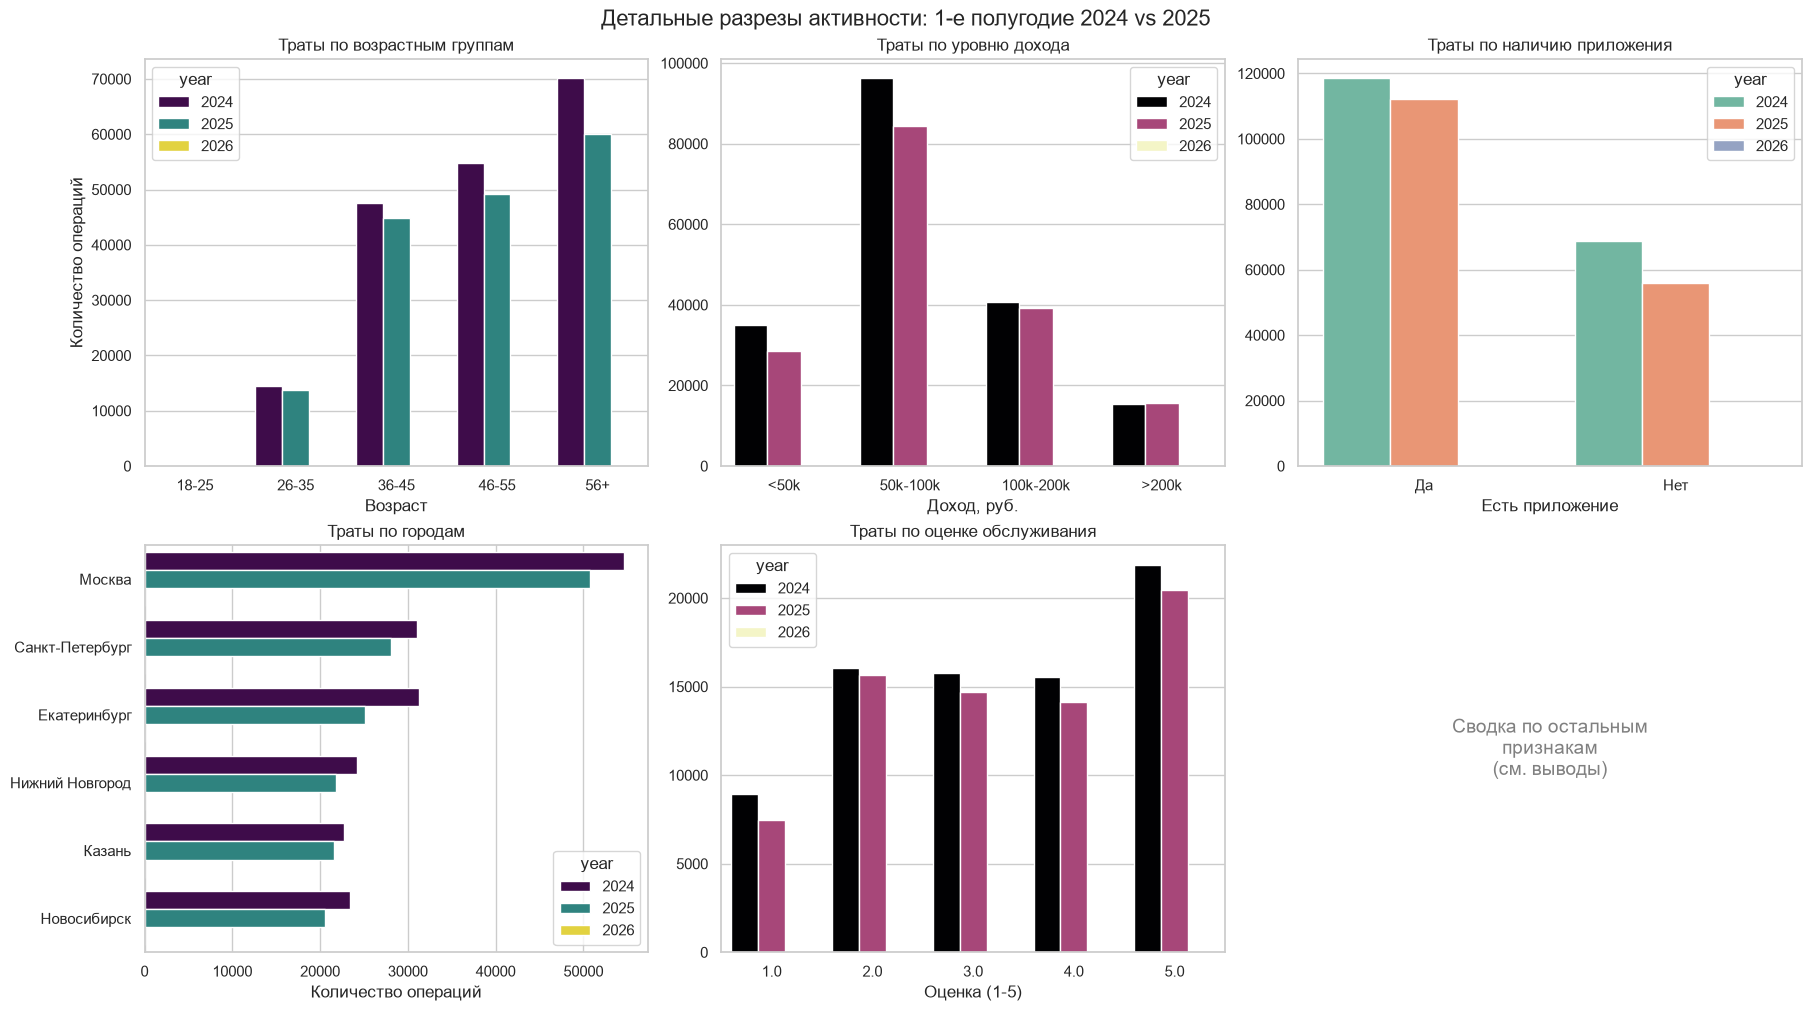

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

txn_success = txn[txn['status'] == 'успешно'].copy()
txn_success['year'] = txn_success['txn_datetime'].dt.year
txn_h1 = txn_success[txn_success['txn_datetime'].dt.month <= 6].copy()

clients_feat = clients.drop_duplicates('client_id').copy()

current_date = pd.Timestamp('2025-06-30')
clients_feat['age'] = (current_date - clients_feat['birth_date']).dt.days // 365

bins_age = [18, 25, 35, 45, 55, 100]
labels_age = ['18-25', '26-35', '36-45', '46-55', '56+']
clients_feat['age_group'] = pd.cut(clients_feat['age'], bins=bins_age, labels=labels_age, right=False)

bins_income = [0, 50000, 100000, 200000, 10000000]
labels_income = ['<50k', '50k-100k', '100k-200k', '>200k']
clients_feat['income_group'] = pd.cut(clients_feat['monthly_income'], bins=bins_income, labels=labels_income, right=False)

cols_to_merge = ['client_id', 'age_group', 'income_group', 'has_mobile_app', 'city', 'satisfaction_score']
txn_merge = txn_h1.merge(clients_feat[cols_to_merge], on='client_id', how='inner')

fig, axes = plt.subplots(2, 3, figsize=(18, 10), layout="constrained")

sns.countplot(data=txn_merge, x='age_group', hue='year', ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Траты по возрастным группам')
axes[0, 0].set_xlabel('Возраст')
axes[0, 0].set_ylabel('Количество операций')

sns.countplot(data=txn_merge, x='income_group', hue='year', ax=axes[0, 1], palette='magma')
axes[0, 1].set_title('Траты по уровню дохода')
axes[0, 1].set_xlabel('Доход, руб.')
axes[0, 1].set_ylabel('')

sns.countplot(data=txn_merge, x='has_mobile_app', hue='year', ax=axes[0, 2], palette='Set2')
axes[0, 2].set_title('Траты по наличию приложения')
axes[0, 2].set_xlabel('Есть приложение')
axes[0, 2].set_ylabel('')

sns.countplot(data=txn_merge, y='city', hue='year', ax=axes[1, 0], palette='viridis', order=txn_merge['city'].value_counts().index)
axes[1, 0].set_title('Траты по городам')
axes[1, 0].set_xlabel('Количество операций')
axes[1, 0].set_ylabel('')

sns.countplot(data=txn_merge.dropna(subset=['satisfaction_score']), x='satisfaction_score', hue='year', ax=axes[1, 1], palette='magma')
axes[1, 1].set_title('Траты по оценке обслуживания')
axes[1, 1].set_xlabel('Оценка (1-5)')
axes[1, 1].set_ylabel('')

axes[1, 2].axis('off') 
axes[1, 2].text(0.5, 0.5, "Сводка по остальным\nпризнакам\n(см. выводы)", 
                ha='center', va='center', fontsize=14, color='gray')

fig.suptitle('Детальные разрезы активности: 1-е полугодие 2024 vs 2025', fontsize=16)
plt.show()

Видим, что основная масса транзакций банка осуществляется клиентами старше 35 лет, у клиентов до 35 лет снижение активности небольшое относительно остальных возрастных групп.

По уровню дохода видно, что частота успешных транзакций сильно уменьшается только у клиентов среднего и низкого уровня дохода, в сегментах клиентов мы наблюдали такую же картину, что доказывает высокую корреляцию между этими двумя признаками. Делаем вывод, что VIP клиенты всем довольны, работать надо с Массовым и зарплатным сегментом или людьми со средним и низким достатком.

По наличию приложения видно, что клиенты с приложением в целом совершают операции чаще, в 2025 году снижение частоты у клиентов с приложением менее заметно и составляет примерно 5%, когда у клиентов без приложения - 15%.

Города и оценки обслуживания влияют на количество успешных транзакций, но не сильно влияют на изменения частоты в 2025 году.



## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

За активность мы принимаем среднемесячное количество успешных транзакций на одного клиента. Использовать оборот будет не корректно, тк один клиент мог совершить крупную покупку, а другой - 100 небольших на ту же сумму, активность второго очевидно выше, но взглянув на оборот мы это не увидим.

Чтобы вычислить активность клиента мы считаем среднее число операций в месяц в базовом и оцениваемом периодах. В базовом периоде берем только те месяца, которые есть в оцениваемом, тк ранее мы наблюдали большой рост частоты транзакций в период новогодних праздников, очевидно, что без их учета в 2025 году у каждого клиента будет пониженная активность.
Среднее в 2024 = (Количество успешных транзакций в 1-м полугодии 2024) / 6 месяцев.
Среднее в 2025 = (Количество успешных транзакций в 1-м полугодии 2025) / 6 месяцев.


Метрика считается только для клиентов, у которых была хотя бы одна успешная транзакция в базовом периоде. потому что если клиент не проявлял активность в базовом периоде, она не могла снизится, также берутся только клиенты, который дали согласие на коммуникацию.
Используются только операции со статусом «успешно», так как отказы и возвраты не отражают реальное потребление.

Базовый период: 01.01.2024 – 30.06.2024 (6 месяцев).
Оцениваемый период: 01.01.2025 – 30.06.2025 (6 месяцев).

Метрика не увидит снижение суммы трат, если клиент раньше делал 10 крупных покупок, а сейчас делает те же 10 покупок, но дешевых, то его активность не упадет, хотя доход банка снизится. Мы не можем увидеть, кто полностью ушел из банка, а кто просто перестал совершать транзакции, мы сталкиваемся с этой проблемой из-за ограничения данных в виде отсутствия даты закрытия карты.

In [62]:
import pandas as pd
import numpy as np

txn_success = txn[txn['status'] == 'успешно'].copy()

h1_2024 = txn_success[
    (txn_success['txn_datetime'] >= '2024-01-01') & 
    (txn_success['txn_datetime'] <= '2024-06-30 23:59:59')
]
h1_2025 = txn_success[
    (txn_success['txn_datetime'] >= '2025-01-01') & 
    (txn_success['txn_datetime'] <= '2025-06-30 23:59:59')
]

base_counts = h1_2024.groupby('client_id').size().reset_index(name='txn_2024')
eval_counts = h1_2025.groupby('client_id').size().reset_index(name='txn_2025')

activity_df = base_counts.merge(eval_counts, on='client_id', how='left')

activity_df['txn_2025'] = activity_df['txn_2025'].fillna(0)
activity_df['avg_2024'] = activity_df['txn_2024'] / 6
activity_df['avg_2025'] = activity_df['txn_2025'] / 6

activity_df['drop_pct'] = ((activity_df['avg_2025'] - activity_df['avg_2024']) / activity_df['avg_2024']) * 100

clients_unique = clients.drop_duplicates('client_id')
clients_opt_in = clients_unique[clients_unique['marketing_opt_in'] == 'Да']

activity_full = activity_df.merge(clients_opt_in, on='client_id', how='inner')

print(f"Всего клиентов с активностью в 1п/г 2024 и согласием на маркетинг: {len(activity_full)}")
print(f"Из них снизили активность (drop_pct < 0): {(activity_full['drop_pct'] < 0).sum()}")

df_target = activity_full[
    (activity_full['drop_pct'] <= -20)
].copy()
print(f"Активность упала на 20% и более: {len(df_target)}")
print(f"Из них полностью перестали тратить: {(df_target['drop_pct'] == -100).sum()}")


Всего клиентов с активностью в 1п/г 2024 и согласием на маркетинг: 4264
Из них снизили активность (drop_pct < 0): 2684
Активность упала на 20% и более: 1947
Из них полностью перестали тратить: 3


## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

### 7.1. Кого в кампанию не берём и почему

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [54]:
# clean.to_parquet("clean_data.parquet", index=False)
# cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
# campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")